# Prédire les short squeezes sur les perpétuels crypto

**Question** : peut-on prédire un short squeeze 24 heures à l'avance à partir du positionnement des traders sur les perpétuels Binance (funding, open interest, ratios long/short, ratio taker) ?

- **H1, shorts informés** : une accumulation de shorts annonce une baisse, et le positionnement ne prédit pas de squeeze.
- **H2, shorts fragiles** : des shorts accumulés avec du levier rendent le marché vulnérable à un rachat forcé.

Pour l'instant, l'analyse porte sur BTC, ETH et SOL, du 2023-01-01 au 2026-09-30, en données horaires.

In [2]:
from src import descriptif
from src.panel_binance import rapport_qualite

panel = descriptif.charger_panel()
panel.groupby("symbol").size()

symbol
BTCUSDT    32856
ETHUSDT    32856
SOLUSDT    32856
dtype: int64

## 1. Données et univers

Avant de définir la cible, on vérifie deux choses : les données sont-elles fiables, et les trois cryptos sont-elles comparables ?

### Valeurs manquantes

Part des heures manquantes (en %) pour les colonnes qui ont au moins un trou, puis leur répartition par mois.

In [3]:
qualite = rapport_qualite(panel)
qualite.loc[:, qualite.sum() > 0].T

symbol,BTCUSDT,ETHUSDT,SOLUSDT
basis,0.15,0.15,0.15
oi,0.03,0.03,0.03
oi_usd,0.03,0.03,0.03
ls_top_comptes,0.03,0.03,0.03
ls_top_positions,0.03,0.03,0.03
ls_global,0.03,0.03,0.03
taker_ratio,0.03,0.03,0.03


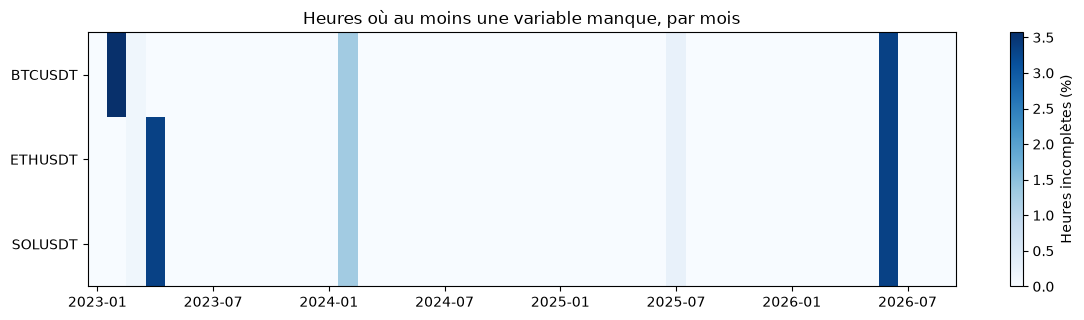

In [4]:
descriptif.graphique_manquants(descriptif.manquants_par_mois(panel))

Les données sont presque complètes : sur 32 856 heures par crypto, aucune variable ne manque plus de 0,15 % du temps. Les trous ont trois origines, toutes chez Binance :
- **la basis** (indice de prime) manque sur des journées entières : le 24 février 2023 pour BTC, le 9 avril 2023 pour ETH et SOL, et le 29 juin 2026 pour les trois. Ce sont les bandes foncées de la carte ;
- **les relevés à 5 minutes** (open interest et ratios) manquent pendant 9 heures le 16 février 2024, sur les trois cryptos à la fois ;
- une heure de spot (24 mars 2023) et deux heures du ratio des gros traders en comptes (22 juillet 2025).

Ces trous sont trop courts pour biaiser l'analyse, et on ne les comble pas. Aucune des variables de la cible (prix, open interest, volumes) ne manque plus de 9 heures.

### Cohérence du ratio taker

La condition C3 de la cible utilise le ratio taker (achats agressifs / ventes agressives). Binance le donne de deux façons :
- **les relevés à 5 minutes** (`taker_ratio` du panel, moyenne des 12 relevés de l'heure) ;
- **les bougies horaires** : `taker_buy_volume / (volume − taker_buy_volume)`.

On compare les deux, heure par heure.

In [5]:
descriptif.comparer_taker(panel).round(3)

,Médiane bougies,Médiane relevés,Médiane relevés / bougies,Corrélation des log,Même côté de 1 (%)
BTCUSDT,0.988,1.094,1.101,0.705,70.222
ETHUSDT,0.984,1.077,1.088,0.688,70.435
SOLUSDT,0.977,1.046,1.064,0.732,73.938


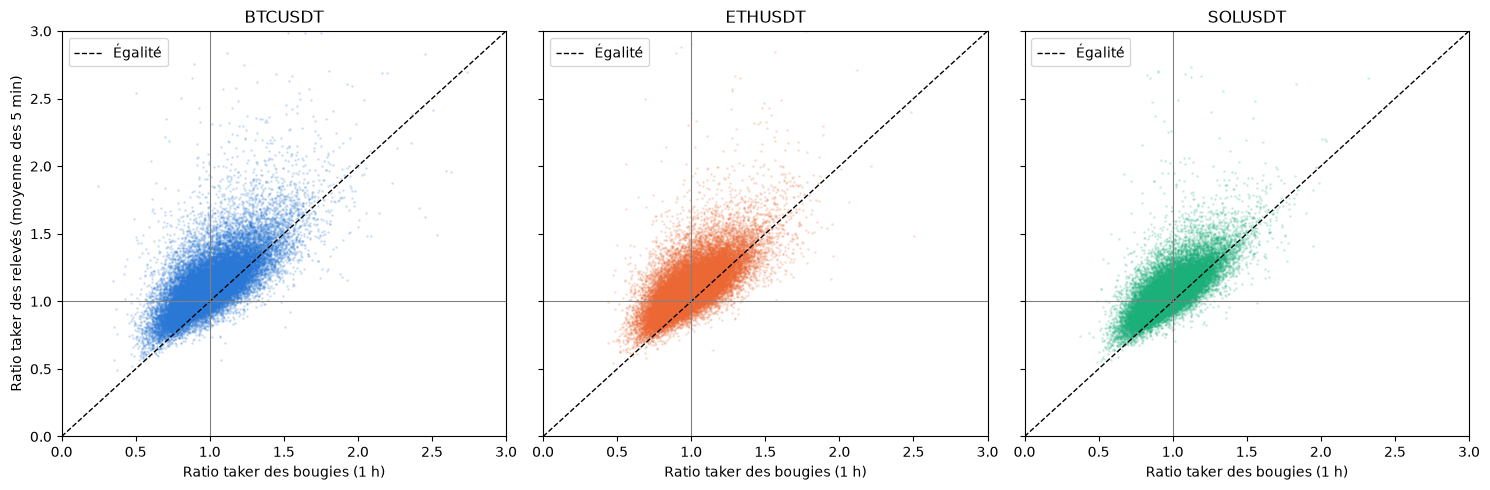

In [6]:
descriptif.graphique_taker(panel)

Les deux mesures vont dans le même sens (corrélation des logarithmes autour de 0,7), mais les relevés sont **6 à 10 % plus élevés** : leur médiane dépasse 1, celle des bougies est en dessous, et le nuage est au-dessus de la diagonale. L'écart vient du calcul : une moyenne de douze ratios est plus grande que le ratio des volumes de l'heure, car un ratio fluctue de façon asymétrique (il ne descend pas sous 0 mais peut monter très haut).

Pour C3, dont le seuil est justement 1, ce choix compte : les deux mesures ne sont du même côté de 1 que 70 à 74 % des heures. Avec la moyenne des relevés, C3 serait vraie plus souvent sans que les acheteurs dominent vraiment. **La cible utilise donc le ratio des bougies**, qui rapporte les volumes réellement échangés pendant l'heure.

### Les trois cryptos

In [7]:
descriptif.tableau_cryptos(panel).round(2)

,Volume quotidien moyen (Md USDT),Open interest moyen (Md USDT),Volatilité annualisée (%),Rendement total (%),Funding moyen annualisé (%),Heures à funding négatif (%),Volume perpétuel / volume spot
BTCUSDT,14.62,5.91,46.08,405.70,7.24,13.56,6.90
ETHUSDT,9.80,3.67,61.14,124.87,7.37,13.90,8.67
SOLUSDT,2.63,0.83,86.31,1082.98,3.86,30.41,5.49


Les trois cryptos ne sont pas comparables en niveau :
- **taille** : BTC échange 14,6 milliards d'USDT par jour sur le perpétuel, SOL cinq fois moins ;
- **volatilité** : SOL est presque deux fois plus volatile que BTC (86 % contre 46 % par an) ;
- **période** : très haussière, de +125 % (ETH) à +1 083 % (SOL), car elle part du creux de fin 2022 ;
- **funding** : positif en moyenne (environ 7 % par an sur BTC et ETH) : les longs paient presque toujours les shorts. Il n'est négatif que 14 % des heures sur BTC et ETH, contre **30 % sur SOL**. Les shorts dominent donc plus souvent sur SOL, la crypto où H2 prévoit le plus de squeezes.

Conséquence : la cible et les variables doivent être relatives à chaque crypto (seuil en écarts-types dans C1, variation relative de l'open interest dans C2, variables normalisées par crypto), pas en niveau.

### Distribution des rendements horaires

In [8]:
descriptif.queues_rendements(panel).round(4)

,Asymétrie,Kurtosis (excès),Au-delà de 4 σ (%)
BTCUSDT,-0.1551,13.2913,0.8644
ETHUSDT,-0.3570,18.1172,0.7792
SOLUSDT,0.1843,11.3202,0.6513
Loi normale,0.0000,0.0000,0.0063


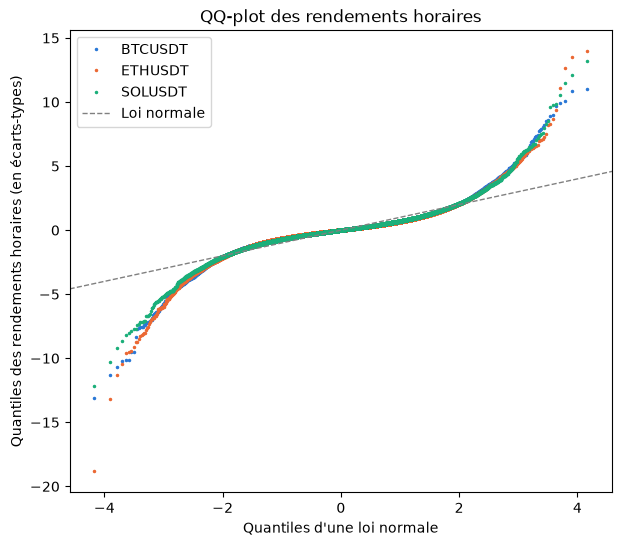

In [9]:
descriptif.graphique_qqplot(panel)

Les rendements horaires ont des **queues très épaisses** : la kurtosis en excès va de 11 à 18 (0 pour une loi normale), et 0,65 à 0,86 % des heures dépassent 4 écarts-types, soit 100 à 140 fois plus qu'avec une loi normale. Sur le QQ-plot, les points quittent la droite dès 2 écarts-types.

Deux conséquences pour la cible :
- **un seuil en écarts-types** est nécessaire, car une même hausse n'a pas le même sens partout. Sur la période, 3·σ·√24 vaut environ 7 % pour BTC, 10 % pour ETH et 14 % pour SOL (volatilité annualisée / √365 × 3). Le plancher de 5 % ne joue donc que dans les périodes calmes ;
- **3 écarts-types ne sont pas un événement à 0,1 %** comme pour une loi normale : les fortes hausses sont plus fréquentes que ne le suggère σ. C'est C2 et C3 qui rendent la cible rare, pas seulement C1.

### Volume du perpétuel et du spot

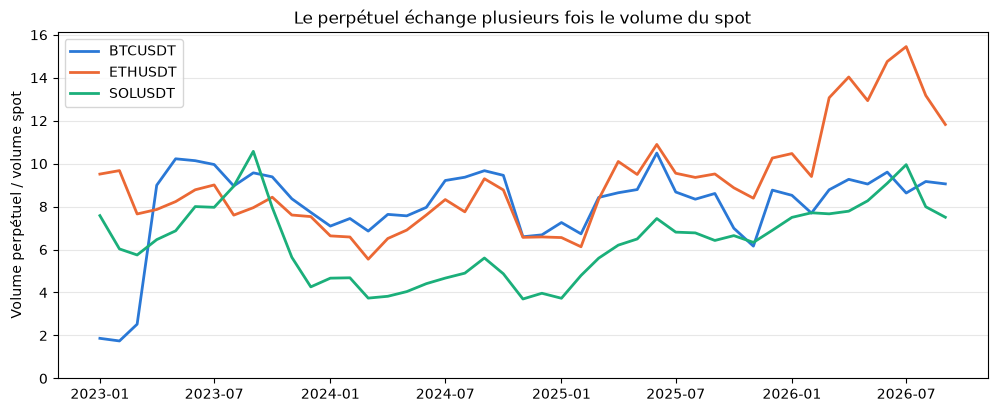

In [10]:
descriptif.graphique_perp_spot(descriptif.ratio_perp_spot_mensuel(panel))

Le perpétuel échange en moyenne **5 à 9 fois le volume du spot** (dernière colonne du tableau des cryptos) : sur ces trois cryptos, l'essentiel des échanges se fait avec levier. C'est ce qui donne du sens à la question : un rachat forcé de shorts sur le perpétuel peut déplacer le prix.

Le rapport varie dans le temps. Il est très bas sur BTC jusqu'en mars 2023 (moins de 3), très probablement parce que Binance supprimait alors les frais sur le spot de BTC, ce qui gonflait son volume. Il monte aussi sur ETH en 2026, jusqu'à 15. S'il sert de variable, il faudra donc le normaliser par crypto et dans le temps.

### Bilan de l'étape 1

- Les données sont fiables : moins de 0,15 % de valeurs manquantes, toujours sur des trous communs venant de Binance.
- Le ratio taker se mesure avec les bougies, pas avec la moyenne des relevés à 5 minutes, qui le surestime.
- Les cryptos diffèrent en taille et en volatilité, et leurs rendements ont des queues épaisses : la cible et les variables doivent être relatives à chaque crypto.

## 2. Variables de positionnement

On décrit les variables qui serviront à départager H1 et H2 :
- **funding** : taux payé par les longs aux shorts (s'il est positif), ramené à 8 h ;
- **variation de l'open interest sur 24 h** : entrée (hausse) ou sortie (baisse) de positions ;
- **trois ratios long/short (L/S)** : nombre de comptes longs divisé par le nombre de comptes courts, pour tous les comptes ou pour les gros traders (les 20 % de comptes qui ont le plus de marge chez Binance), et, pour les gros traders, le même rapport pondéré par la taille des positions ;
- **ratio taker** : achats agressifs / ventes agressives de l'heure, calculé avec les bougies (voir l'étape 1) ;
- **basis** : écart entre le prix du perpétuel et l'indice au comptant.

In [11]:
variables = descriptif.positionnement(panel)
descriptif.resume_positionnement(variables).round(3)

Min     1 %  Médiane    99 %     Max
Funding (% par 8 h)         BTCUSDT  -0.015  -0.008    0.006   0.044   0.088
                            ETHUSDT  -0.037  -0.009    0.006   0.046   0.102
                            SOLUSDT  -0.927  -0.040    0.005   0.056   0.119
Variation OI 24 h (%)       BTCUSDT -25.882  -9.696   -0.010   9.255  24.883
                            ETHUSDT -28.755 -10.281    0.010  11.664  42.471
                            SOLUSDT -29.217 -12.718   -0.062  14.487  58.115
L/S tous comptes            BTCUSDT   0.418   0.530    1.361   2.974   4.173
                            ETHUSDT   0.521   0.782    2.149   4.975   6.314
                            SOLUSDT   0.536   0.814    2.409   5.004   6.029
L/S gros traders, comptes   BTCUSDT   0.503   0.632    1.414   3.218   5.148
                            ETHUSDT   0.537   0.795    2.249   6.224   8.587
                            SOLUSDT   0.574   0.857    2.546   5.513   6.481
L/S gros traders, positions BTCUSDT   0.683   0.790    1.379   2.406   2.821
                            ETHUSDT   0.878   1.027    1.778   4.496   6.120
                            SOLUSDT   0.858   0.940    1.763   3.468   3.961
Ratio taker                 BTCUSDT   0.243   0.609    0.988   1.594   2.739
                            ETHUSDT   0.435   0.645    0.984   1.515   3.332
                            SOLUSDT   0.372   0.654    0.977   1.440   2.320
Basis (%)                   BTCUSDT  -0.816  -0.075   -0.041   0.103   0.427
                            ETHUSDT  -0.659  -0.082   -0.040   0.105   0.568
                            SOLUSDT  -2.067  -0.113   -0.041   0.125   1.096

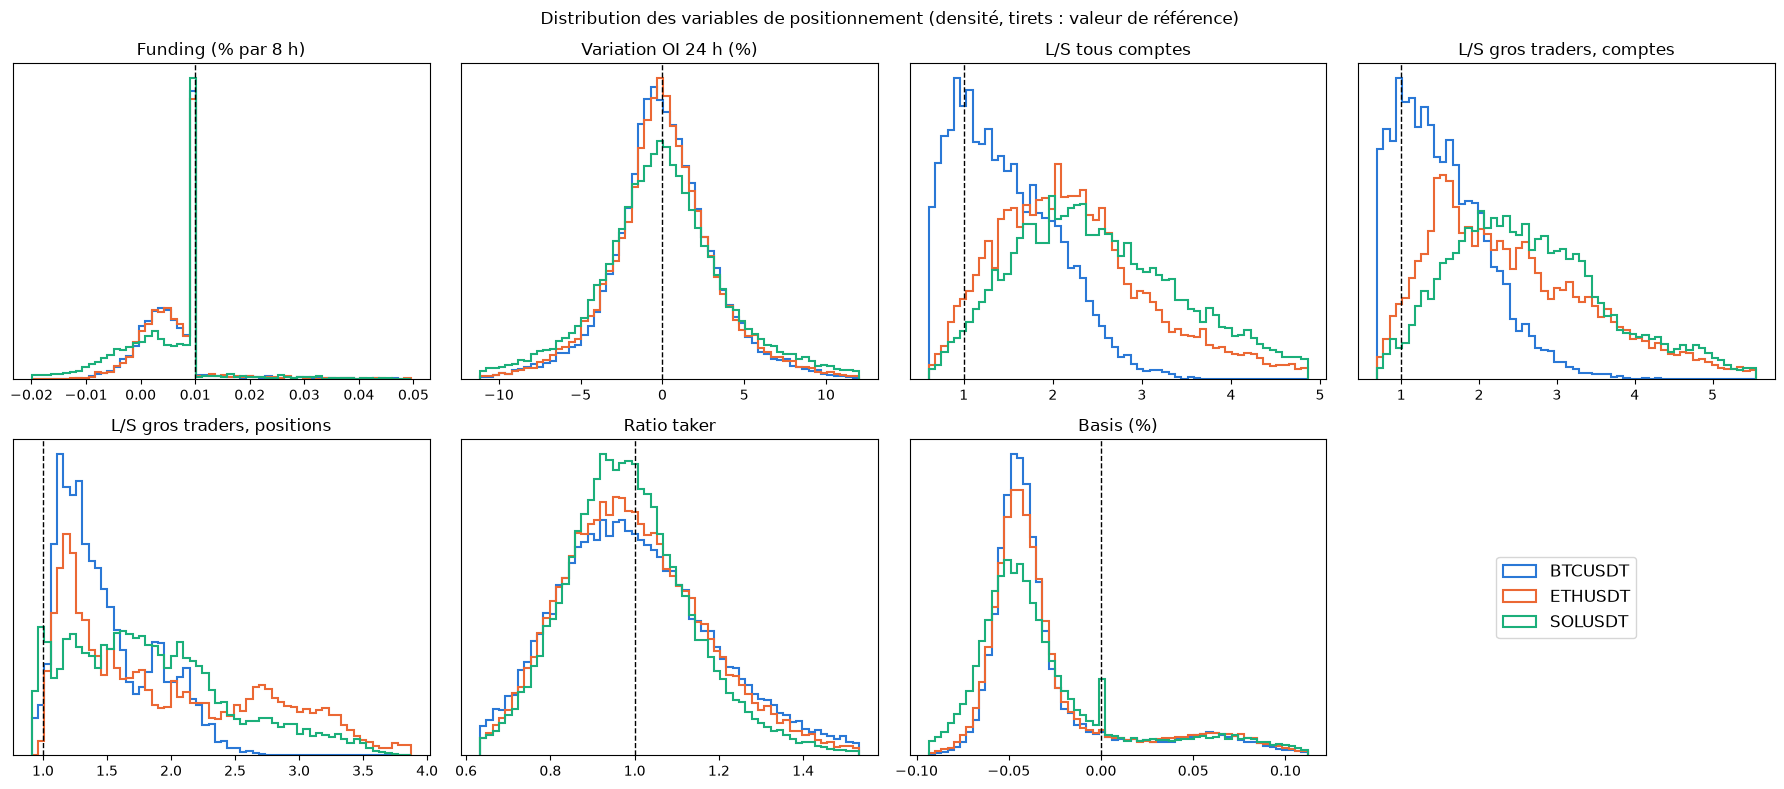

In [12]:
descriptif.graphique_distributions(variables)

- **Funding** : une grande partie des heures tombe exactement sur 0,01 % par 8 h, le taux par défaut de Binance (pic du premier histogramme). Le reste est surtout un peu en dessous ; au-dessus, il ne dépasse 0,044 à 0,056 % que 1 % du temps. Le minimum, −0,93 % par 8 h sur SOL le 4 janvier 2023, tombe pendant la hausse de SOL de janvier 2023 : les shorts payaient très cher pour rester en position. C'est le cas typique de H2, à retrouver dans la cible à l'étape 3.
- **Ratios L/S en comptes** : presque toujours au-dessus de 1 (médiane 1,4 pour BTC, 2,1 pour ETH, 2,4 pour SOL). En nombre de comptes, les longs dominent. « Beaucoup de shorts » ne peut donc pas vouloir dire un ratio sous 1 : il faut une mesure relative au niveau habituel de chaque crypto.
- **Ratio L/S des gros traders en positions** : plus proche de 1 et jamais sous 0,68.
- **Ratio taker** : centré un peu sous 1 (0,98) et assez symétrique ; 98 % des heures sont entre 0,61 et 1,59.
- **Variation de l'open interest** : dans ±10 à 15 % sur 24 h pour 98 % des heures, avec des chutes de 26 à 29 % (krachs) et une hausse de 58 % sur SOL.
- **Basis** : négative en médiane (−0,04 %), avec une seconde bosse vers +0,05 à +0,10 %, surtout dans les phases de hausse (fin 2023 à mars 2024, novembre 2024). Le petit pic à exactement 0 (1,7 % des heures de SOL, surtout en 2023) reste à expliquer.

### Le funding au taux par défaut

Binance verse le taux par défaut quand la prime du perpétuel sur l'indice est faible. Part des heures où le funding est sous, au ou au-dessus de ce taux, par année :

In [13]:
descriptif.position_du_funding(panel).round(1)

En dessous  Au taux par défaut  Au-dessus
symbol  année                                           
BTCUSDT 2023         55.2                38.5        6.3
        2024         38.5                42.1       19.4
        2025         82.8                17.2        0.0
        2026         93.2                 6.8        0.0
ETHUSDT 2023         55.8                37.2        7.0
        2024         38.3                39.6       22.0
        2025         80.6                19.4        0.0
        2026         94.6                 5.4        0.0
SOLUSDT 2023         49.9                41.2        9.0
        2024         40.6                36.7       22.7
        2025         80.5                19.3        0.2
        2026         86.7                13.3        0.0

Deux régimes se succèdent. En 2023-2024, le funding est au taux par défaut environ 40 % des heures et au-dessus 6 à 23 % des heures. En 2025-2026, il est en dessous 80 à 95 % des heures et **presque jamais au-dessus** (0,2 % des heures au plus) : les longs ne paient plus de prime. La même rupture apparaît sur Bybit, ce n'est donc pas une erreur des fichiers Binance. Une valeur au taux par défaut dit seulement que le marché n'est pas tendu ; l'information est dans les écarts à ce taux, et leur sens a changé entre les deux périodes. Pour les variables, on utilisera donc l'écart au taux par défaut plutôt que le niveau.

### Évolution de 2023 à 2026

Moyennes quotidiennes ; les pointillés marquent trois événements de marché.

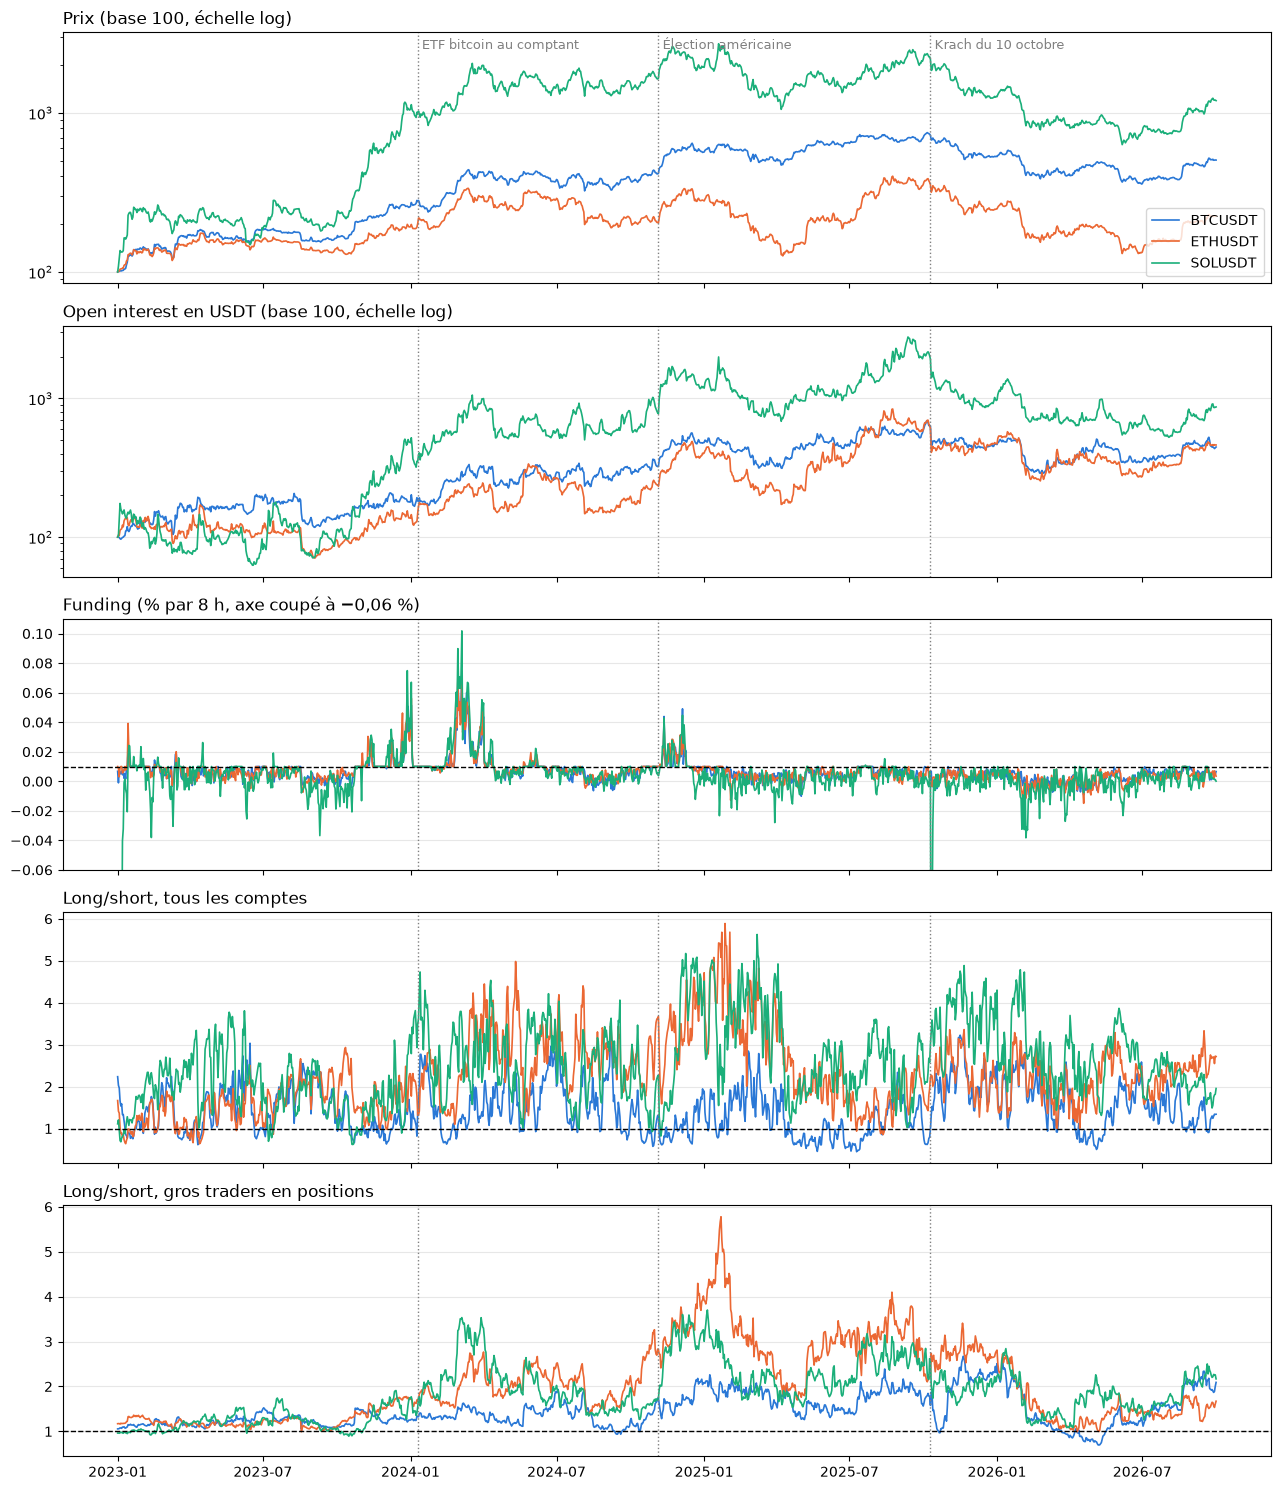

In [14]:
descriptif.graphique_series(panel, variables)

In [15]:
descriptif.medianes_par_an(variables).round(3)

Funding (% par 8 h)  Variation OI 24 h (%)  L/S tous comptes  \
symbol  année                                                                 
BTCUSDT 2023                 0.008                  0.063             1.298   
        2024                 0.010                  0.172             1.353   
        2025                 0.005                 -0.129             1.325   
        2026                 0.003                 -0.148             1.472   
ETHUSDT 2023                 0.008                 -0.063             1.539   
        2024                 0.010                  0.165             2.740   
        2025                 0.005                  0.005             2.260   
        2026                 0.003                 -0.088             2.222   
SOLUSDT 2023                 0.010                 -0.205             1.822   
        2024                 0.010                  0.105             2.666   
        2025                 0.002                 -0.047             2.890   
        2026                 0.000                 -0.133             2.456   

               L/S gros traders, comptes  L/S gros traders, positions  \
symbol  année                                                           
BTCUSDT 2023                       1.246                        1.208   
        2024                       1.438                        1.374   
        2025                       1.457                        1.853   
        2026                       1.570                        1.314   
ETHUSDT 2023                       1.519                        1.209   
        2024                       3.100                        2.114   
        2025                       2.639                        2.905   
        2026                       1.910                        1.407   
SOLUSDT 2023                       1.734                        1.185   
        2024                       2.730                        1.954   
        2025                       3.189                        2.174   
        2026                       2.773                        1.657   

               Ratio taker  Basis (%)  
symbol  année                          
BTCUSDT 2023         0.991     -0.038  
        2024         0.983     -0.025  
        2025         0.979     -0.044  
        2026         1.001     -0.047  
ETHUSDT 2023         0.990     -0.037  
        2024         0.975     -0.026  
        2025         0.979     -0.044  
        2026         0.993     -0.048  
SOLUSDT 2023         0.985     -0.030  
        2024         0.969     -0.026  
        2025         0.971     -0.047  
        2026         0.983     -0.050

- **Phases du marché** : début 2024 (ETF bitcoin) et fin 2024 (élection américaine), les prix et l'open interest montent ensemble et le funding dépasse nettement le taux par défaut : les longs paient cher, le marché est tendu à la hausse. En 2025-2026, le funding passe plus souvent sous le taux par défaut, et devient franchement négatif sur SOL au moment du krach du 10 octobre 2025.
- **Les niveaux dérivent** : la médiane du ratio L/S de tous les comptes sur ETH passe de 1,5 en 2023 à 2,7 en 2024 ; celle du ratio des gros traders en positions sur BTC passe de 1,2 en 2023 à 1,9 en 2025, puis 1,3 en 2026.

Un même niveau n'a donc pas le même sens selon l'année et la crypto. Les variables seront des **z-scores glissants par crypto** (écart à la moyenne des 30 derniers jours, divisé par l'écart-type), à construire dans `variables.py`.

### Corrélations entre variables

Corrélations de rang (Spearman), moins sensibles aux valeurs extrêmes que celles de Pearson.

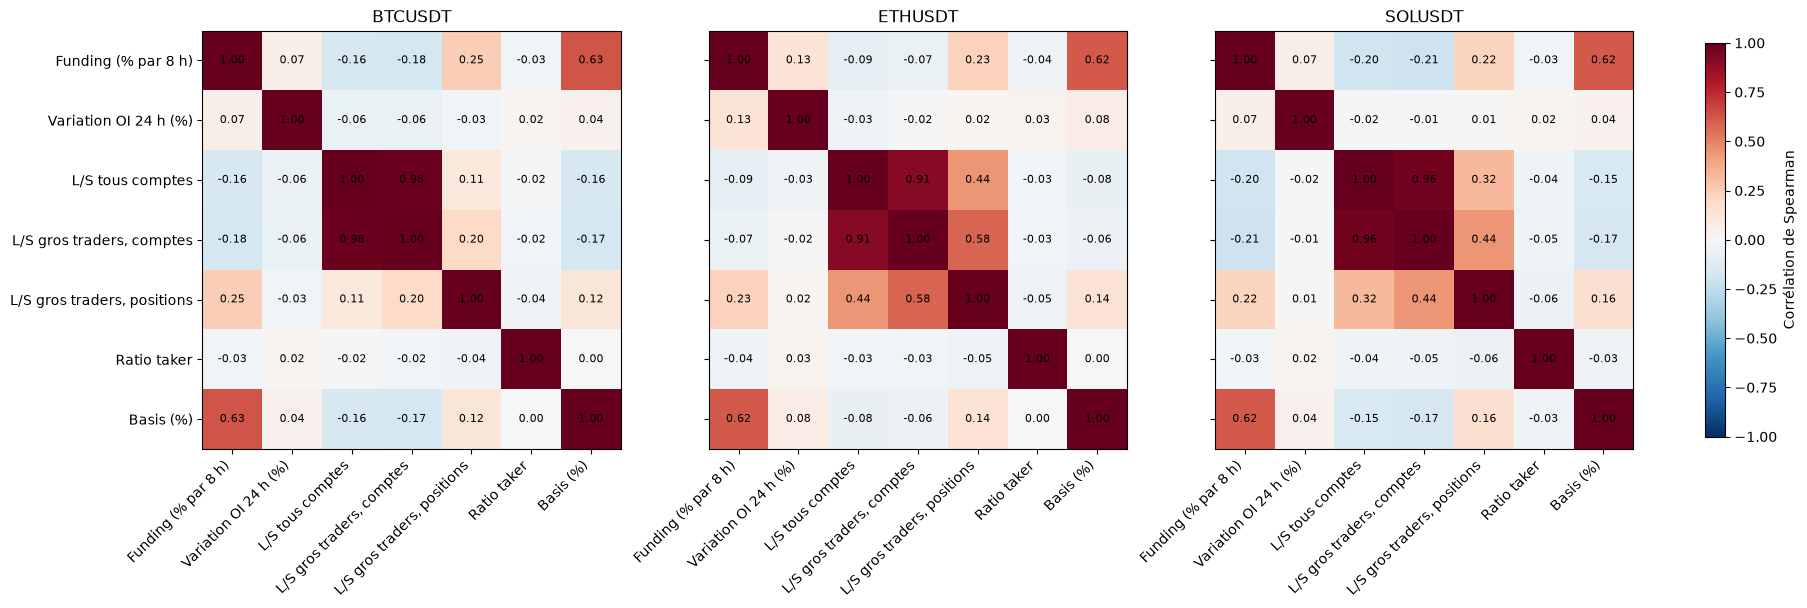

In [16]:
descriptif.graphique_correlations(variables)

- **Les deux ratios en comptes sont presque identiques** (0,91 à 0,98) : ils portent la même information, et les mettre ensemble dans le logit poserait un problème de multicolinéarité. On n'en gardera qu'un.
- **Le ratio en positions est différent** (0,11 à 0,58 avec les ratios en comptes) : il mesure la taille des paris, pas le nombre de parieurs.
- **Funding et basis** (0,62) : lien en partie mécanique, car Binance calcule le funding à partir de la prime du perpétuel.
- **La variation d'open interest et le ratio taker** ne sont corrélés à rien (moins de 0,15 en valeur absolue) : ils apportent une information à part.

### Positionnement et rendement passé

Le modèle « prix seuls » servira de point de comparaison. Il faut donc savoir quelle part du positionnement reflète simplement le prix : corrélation de chaque variable avec le rendement des 7 derniers jours.

In [17]:
descriptif.correlations_rendement_passe(panel, variables).round(2)

,BTCUSDT,ETHUSDT,SOLUSDT
Funding (% par 8 h),0.20,0.33,0.34
Variation OI 24 h (%),0.05,0.08,0.04
L/S tous comptes,-0.69,-0.51,-0.62
"L/S gros traders, comptes",-0.66,-0.47,-0.53
"L/S gros traders, positions",-0.07,-0.01,0.03
Ratio taker,0.05,0.02,0.03
Basis (%),0.20,0.26,0.28


Les ratios en comptes sont **fortement liés au rendement passé** (−0,5 à −0,7) : quand le prix baisse, une plus grande part des comptes est longue, comme si beaucoup de comptes achetaient la baisse. Le ratio des gros traders en positions n'y est pas lié (entre −0,07 et 0,03), et le funding l'est un peu, dans l'autre sens (0,2 à 0,34).

Conséquence pour la question : une bonne part de l'information des ratios en comptes est déjà dans les prix. Le modèle « prix seuls » est donc un point de comparaison exigeant, et c'est surtout le ratio en positions qui peut apporter une information que le prix n'a pas.

### Persistance

Autocorrélation de chaque variable avec elle-même 1 heure, 24 heures et 7 jours plus tôt, en moyenne sur les trois cryptos.

In [18]:
descriptif.persistance(variables).round(2)

,1 h,24 h,7 jours
Variable,,,
Funding (% par 8 h),0.97,0.63,0.43
Variation OI 24 h (%),0.97,-0.12,-0.03
L/S tous comptes,1.00,0.87,0.58
"L/S gros traders, comptes",1.00,0.89,0.68
"L/S gros traders, positions",1.00,0.98,0.90
Ratio taker,-0.01,0.01,0.01
Basis (%),0.84,0.73,0.60


- **Les ratios L/S évoluent lentement** : 0,87 à 0,98 à 24 h, et encore 0,58 à 0,90 à 7 jours. Ils décrivent un état du marché plutôt qu'un choc. Un signal extrême reste donc présent plusieurs jours : c'est une raison de plus pour une validation temporelle avec un trou entre apprentissage et test.
- **Le funding** est persistant lui aussi (0,63 à 24 h). Son 0,97 à 1 h est en partie mécanique : le taux ne change qu'à chaque paiement, toutes les 8 h.
- **La variation de l'open interest sur 24 h** : le 0,97 à 1 h est mécanique, car deux fenêtres de 24 h décalées d'une heure ont 23 heures en commun. À 24 h, il n'y a plus de persistance (−0,12).
- **Le ratio taker** n'a aucune mémoire, même d'une heure à l'autre (−0,01). Comme variable, il faudra le moyenner sur plusieurs heures.

### Bilan de l'étape 2

- Les niveaux des ratios et du funding changent selon la crypto et l'année : on utilisera des z-scores glissants par crypto, et l'écart du funding au taux par défaut.
- Les deux ratios L/S en comptes sont redondants, et très liés au rendement passé ; le ratio des gros traders en positions apporte une information distincte du prix.
- Les variables lentes (ratios, funding) décrivent un état du marché, les variables rapides (ratio taker, variation d'open interest) des chocs : les deux familles se complètent.

## 3. La cible

Une heure t est positive s'il y a un short squeeze dans les 24 heures qui suivent, c'est-à-dire si les trois conditions sont réunies :
- **C1, forte hausse** : le plus haut des 24 h suivantes dépasse le prix de clôture connu à t d'au moins max(3·σ·√24, 5 %), σ étant l'écart-type des rendements horaires des 30 derniers jours ;
- **C2, rachat des shorts** : entre t et ce pic, l'open interest baisse d'au moins 10 % ;
- **C3, pression acheteuse** : entre t et le pic, les achats agressifs dépassent les ventes agressives (ratio taker > 1).

La cible est calculée par `src/cible.py` sur le panel complet, car σ a besoin des 30 jours de chauffe, puis on garde la période d'étude. Les dernières heures de la série n'ont pas 24 h de futur : leur cible est inconnue.

Avec une fenêtre de 24 h, un même squeeze rend positives plusieurs heures t de suite. On compte donc aussi des **épisodes** : deux heures positives à moins de 24 h d'écart appartiennent au même épisode, car leurs fenêtres se chevauchent. Chaque épisode est décrit par son heure à la plus forte hausse.

In [31]:
from src.cible import ajouter_cible

panel_complet = descriptif.charger_panel(avec_chauffe=True)
panel_cible_complet = ajouter_cible(panel_complet)
panel_cible = descriptif.periode_etude(panel_cible_complet)
episodes_cible = descriptif.tableau_episodes(panel_cible)
episodes_cible.round(2)

C:\Users\duviv\AppData\Local\Temp\ipykernel_19064\2859423527.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  episodes_cible.round(2)


,symbol,debut,fin,heures_positives,date_pic,delai_pic_h,hausse_pic_pct,variation_oi_pct,ratio_achats_ventes
0,BTCUSDT,2023-01-13 02:00:00+00:00,2023-01-14 00:00:00+00:00,17,2023-01-14 01:00:00+00:00,23.0,14.55,-10.06,1.08
1,BTCUSDT,2023-01-20 11:00:00+00:00,2023-01-20 20:00:00+00:00,10,2023-01-21 11:00:00+00:00,23.0,11.32,-11.76,1.09
2,BTCUSDT,2023-10-15 14:00:00+00:00,2023-10-16 13:00:00+00:00,18,2023-10-16 14:00:00+00:00,24.0,14.41,-12.39,1.09
3,BTCUSDT,2024-02-27 18:00:00+00:00,2024-02-28 13:00:00+00:00,9,2024-02-28 18:00:00+00:00,24.0,13.20,-10.54,1.04
4,ETHUSDT,2023-01-13 01:00:00+00:00,2023-01-14 00:00:00+00:00,24,2023-01-14 01:00:00+00:00,11.0,17.13,-15.84,1.13
5,ETHUSDT,2023-03-12 05:00:00+00:00,2023-03-12 12:00:00+00:00,8,2023-03-13 01:00:00+00:00,18.0,11.39,-11.64,1.10
6,ETHUSDT,2023-06-16 06:00:00+00:00,2023-06-16 11:00:00+00:00,6,2023-06-17 06:00:00+00:00,21.0,6.32,-10.45,1.10
7,ETHUSDT,2024-02-26 10:00:00+00:00,2024-02-26 14:00:00+00:00,5,2024-02-27 03:00:00+00:00,17.0,8.30,-11.32,1.06
8,SOLUSDT,2023-01-01 08:00:00+00:00,2023-01-02 07:00:00+00:00,24,2023-01-02 08:00:00+00:00,23.0,24.16,-11.68,1.11
9,SOLUSDT,2023-01-08 02:00:00+00:00,2023-01-08 20:00:00+00:00,19,2023-01-09 16:00:00+00:00,21.0,29.37,-12.12,1.08


On trouve **16 épisodes** : 4 pour BTC, 4 pour ETH et 8 pour SOL. Ils regroupent 199 heures positives, soit 12 heures en moyenne par épisode.

### Fréquence

Nombre d'heures positives et d'épisodes, par crypto et par année.

In [20]:
descriptif.frequence_cible(panel_cible, episodes_cible).round(3)

heures  heures_positives  episodes  part_positive_pct
symbol  année                                                       
BTCUSDT 2023     8760                45         3              0.514
        2024     8784                 9         1              0.102
        2025     8760                 0         0              0.000
        2026     6528                 0         0              0.000
        Total   32832                54         4              0.164
ETHUSDT 2023     8760                38         3              0.434
        2024     8784                 5         1              0.057
        2025     8760                 0         0              0.000
        2026     6528                 0         0              0.000
        Total   32832                43         4              0.131
SOLUSDT 2023     8760               101         7              1.153
        2024     8784                 0         0              0.000
        2025     8760                 0         0              0.000
        2026     6528                 1         1              0.015
        Total   32832               102         8              0.311

- **Les squeezes sont très rares** : 0,13 % des heures pour ETH, 0,16 % pour BTC et 0,31 % pour SOL. Ces parts sont la **base naïve** de la PR-AUC : un modèle qui tirerait au hasard aurait cette précision. Avec si peu de positifs, l'accuracy n'a aucun sens : un modèle qui répond toujours « pas de squeeze » aurait raison 99,7 % du temps.
- **Ils se concentrent en 2023** : 13 épisodes sur 16. Il y en a 2 en 2024, aucun en 2025, et un seul en 2026 (SOL, août).
- **Conséquence pour la validation** : si la période de test couvre 2025-2026, elle ne contiendra presque aucun squeeze, et la PR-AUC y sera très instable. Le découpage temporel devra en tenir compte, par exemple avec plusieurs plis successifs plutôt qu'un seul.

### Entonnoir C1 → C1 + C2 → C1 + C2 + C3

Parmi les heures qui connaissent une forte hausse (C1), combien s'accompagnent d'une baisse de l'open interest (C2), puis d'une pression acheteuse (C3) ? La deuxième barre compte les fortes hausses pendant lesquelles l'open interest **monte** : de nouvelles positions s'ouvrent, ce n'est pas un rachat de shorts.

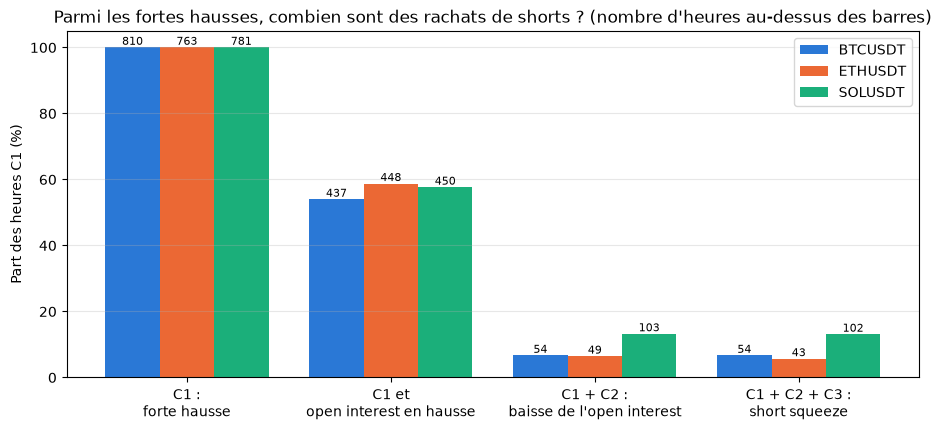

In [21]:
descriptif.graphique_entonnoir(descriptif.entonnoir(panel_cible))

- **Les fortes hausses sont courantes** (760 à 810 heures par crypto), mais **plus de la moitié** (54 à 59 %) se font avec un open interest en hausse : elles viennent de nouveaux longs, pas d'un rachat de shorts.
- **C2 fait presque tout le tri** : il ne reste que 6 à 13 % des heures C1. C'est elle qui sépare un squeeze d'une simple hausse, et elle correspond bien au mécanisme visé.
- **C3 n'enlève presque rien** (54 → 54 pour BTC, 49 → 43 pour ETH, 103 → 102 pour SOL) : quand les shorts sont rachetés, les achats agressifs dominent presque toujours. C3 confirme le mécanisme mais n'apporte presque pas d'information.

### Simultanéité

Parmi les heures positives d'une crypto (ligne), part des heures où une autre crypto (colonne) est aussi positive.

In [22]:
descriptif.simultaneite(panel_cible).round(1)

symbol,BTCUSDT,ETHUSDT,SOLUSDT,Au moins une autre
symbol,,,,
BTCUSDT,100.0,31.5,31.5,31.5
ETHUSDT,39.5,100.0,74.4,74.4
SOLUSDT,16.7,31.4,100.0,31.4


- **Les squeezes sont souvent communs à plusieurs cryptos** : 31 % des heures positives de BTC et de SOL, et 74 % de celles d'ETH, le sont aussi pour une autre crypto.
- Trois mouvements de marché regroupent 7 des 16 épisodes : le **13-14 janvier 2023** (les trois cryptos), le **rebond de mars 2023** après la crise de SVB et de l'USDC (ETH et SOL), et **fin février 2024** (BTC et ETH).
- Un squeeze est donc souvent un événement de marché plus qu'une affaire propre à une crypto. Les positifs ne sont pas indépendants d'une crypto à l'autre, ce qui réduit encore le nombre d'événements réellement distincts.

### Calendrier

Heure UTC et jour de la semaine du pic de chaque épisode.

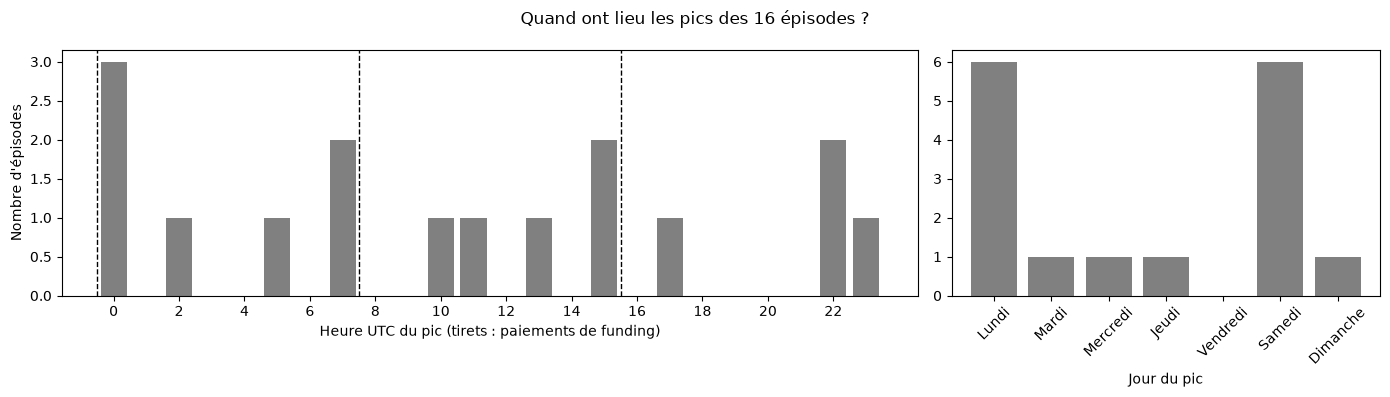

In [23]:
descriptif.graphique_calendrier(episodes_cible)

- **Pas d'heure privilégiée** : les pics sont dispersés sur la journée, sans regroupement visible juste avant ou après les paiements de funding (00 h, 08 h, 16 h UTC).
- **Le samedi et le lundi ressortent** (6 épisodes chacun), mais c'est surtout un effet de la simultanéité : le samedi 14 janvier 2023 compte à lui seul trois épisodes, et le lundi 13 mars 2023 deux.
- Avec 16 épisodes, ces répartitions ne permettent pas de conclure à un effet de calendrier. On ne s'en servira pas comme variable.

### Profil d'un squeeze

Valeurs médianes par crypto : nombre d'heures positives, délai entre t et le pic, hausse au pic, variation de l'open interest et ratio taker entre t et le pic.

In [24]:
descriptif.profil_episodes(episodes_cible).round(2)

,episodes,heures_positives,delai_pic_h,hausse_pic_pct,variation_oi_pct,ratio_achats_ventes
symbol,,,,,,
BTCUSDT,4,13.5,23.5,13.81,-11.15,1.08
ETHUSDT,4,7.0,17.5,9.85,-11.48,1.10
SOLUSDT,8,13.0,21.5,17.89,-11.76,1.07


- **Ampleur** : la hausse médiane va de 10 % (ETH) à 18 % (SOL), en accord avec la volatilité de chaque crypto. Le plus gros épisode est celui de SOL en janvier 2023 (+50 % en 19 heures).
- **Délai** : le pic arrive en médiane 17 à 24 heures après t, souvent au bout de la fenêtre. Les squeezes sont des hausses qui durent, pas des pics d'une heure.
- **L'open interest baisse de 11 à 12 % en médiane**, juste au-delà du seuil de 10 % : beaucoup d'épisodes passent C2 de peu. La cible sera donc sensible au choix de δ (voir ci-dessous).
- **Le ratio taker** n'est que légèrement supérieur à 1 (1,07 à 1,10), ce qui confirme que C3 est peu exigeante.

### Sensibilité aux seuils

Part des heures positives et nombre d'épisodes quand on change un seul seuil de la cible.

In [25]:
descriptif.sensibilite(panel_complet).round(3)

Heures positives (%)                 Épisodes                
                          BTCUSDT ETHUSDT SOLUSDT  BTCUSDT ETHUSDT SOLUSDT
Base                        0.164   0.131   0.311      4.0     4.0     8.0
k = 2,5                     0.168   0.143   0.347      4.0     4.0    11.0
k = 4                       0.152   0.073   0.241      4.0     1.0     6.0
Plancher 3 %                0.164   0.131   0.311      4.0     4.0     8.0
Plancher 8 %                0.164   0.101   0.311      4.0     3.0     8.0
δ = 5 %                     0.591   0.408   0.573     11.0    15.0    17.0
δ = 15 %                    0.000   0.046   0.122      0.0     1.0     4.0
Horizon 12 h                0.113   0.046   0.140      5.0     3.0     6.0
Horizon 48 h                0.256   0.195   0.418      4.0     4.0     8.0

- **δ (la baisse d'open interest exigée) est le seuil qui compte** : à 5 %, les heures positives sont 2 à 4 fois plus nombreuses (11 à 17 épisodes par crypto) ; à 15 %, BTC n'a plus aucun squeeze et SOL n'en garde que 4. Comme l'a montré le profil, la plupart des squeezes passent C2 de peu.
- **k compte moins** : passer de 3 à 2,5 ou à 4 change surtout SOL et ETH, et laisse BTC intact.
- **Le plancher ne joue presque pas** : le seuil 3·σ·√24 est presque toujours au-dessus de 5 %. Seul un épisode d'ETH (+6,3 %) disparaît avec un plancher de 8 %.
- **L'horizon** : à 12 h, il y a 1,5 à 3 fois moins d'heures positives ; à 48 h, plus d'heures positives, mais à peu près les mêmes épisodes.

Les résultats de la suite devront être vérifiés avec δ = 5 %, qui donne environ trois fois plus d'épisodes et des estimations moins fragiles.

### Deux exemples

Prix, open interest, funding et ratio long/short de tous les comptes, de 3 jours avant le début de l'épisode (tirets rouges) à 1 jour après le pic (tirets noirs).

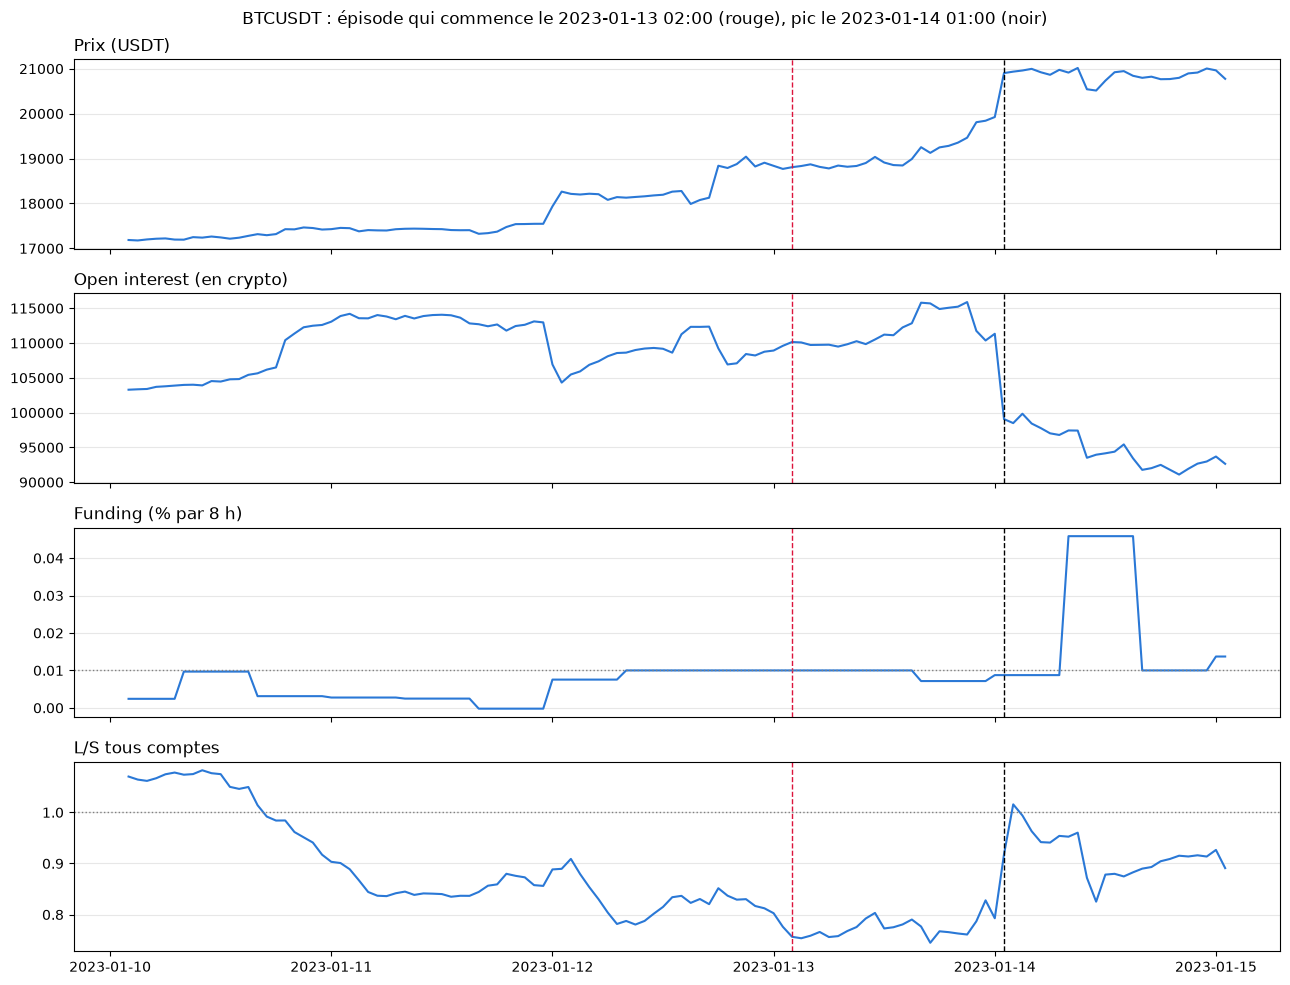

In [26]:
descriptif.graphique_episode(panel_cible, "BTCUSDT", "2023-01-13 02:00")

**BTC, 13-14 janvier 2023.** Le prix monte de 17 200 à 21 000 USDT en quatre jours. Avant le pic, le ratio long/short est bas (0,75 à 0,85) : une majorité de comptes est à découvert. Au pic, l'open interest chute d'un coup de 115 000 à 99 000 BTC et le ratio remonte au-dessus de 1 : les shorts ont été rachetés. Le funding, lui, reste proche du taux par défaut jusqu'au pic et ne signale rien.

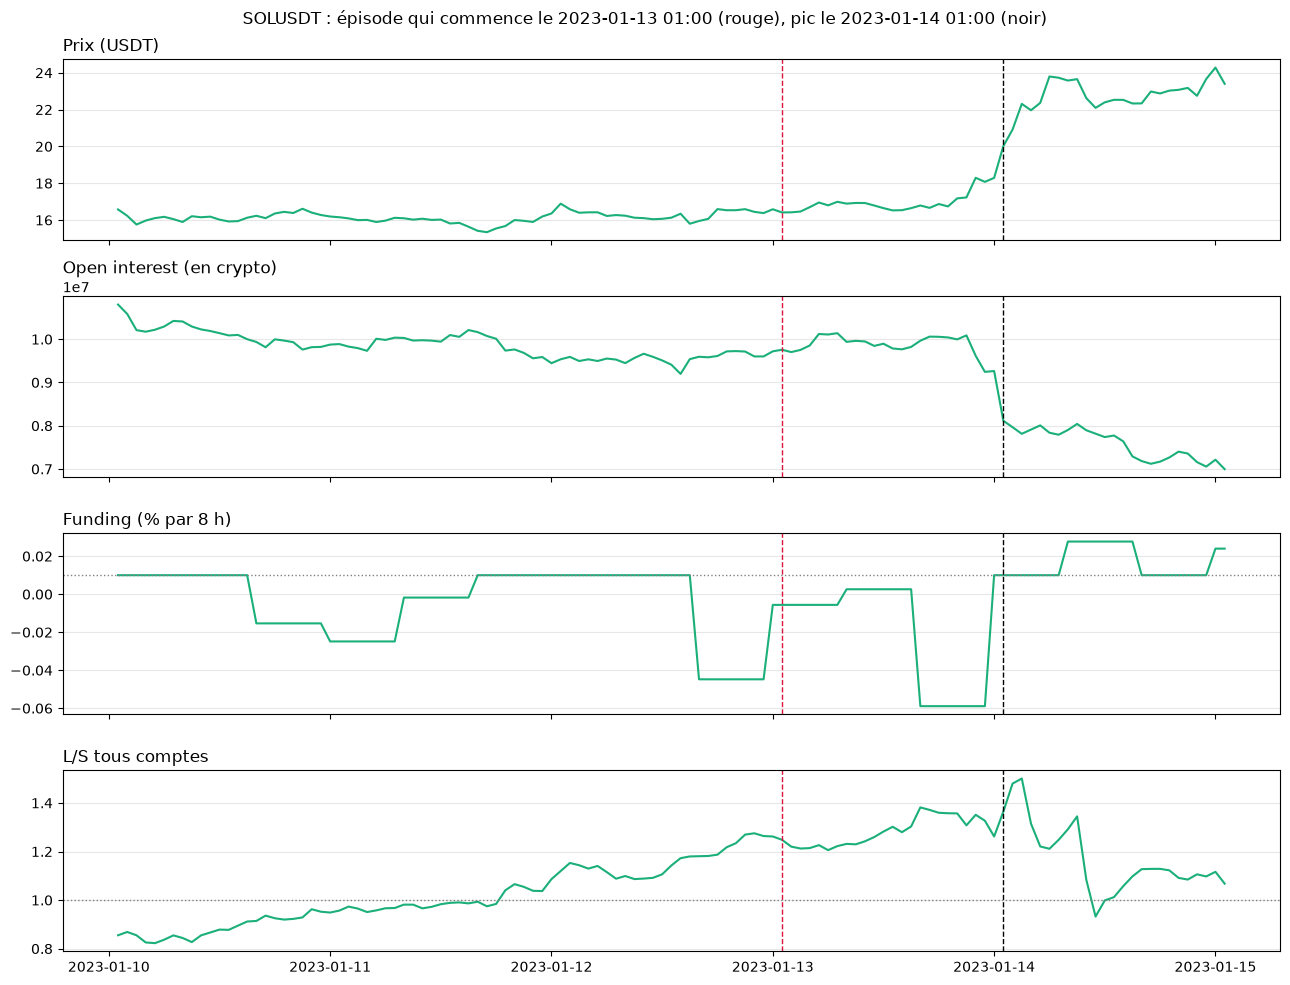

In [27]:
descriptif.graphique_episode(panel_cible, "SOLUSDT", "2023-01-13 01:00")

**SOL, 13-14 janvier 2023.** Le prix passe de 16 à 23,7 USDT, et l'open interest baisse de près de 30 %. Ici, c'est le **funding** qui signale les shorts : il est négatif avant le pic (jusqu'à −0,06 % par 8 h), les shorts payaient donc pour garder leur position. Le ratio long/short est au contraire au-dessus de 1 : il compte les comptes, pas la taille des positions.

Les deux exemples vont dans le sens de H2 (des shorts nombreux puis rachetés), mais par des variables différentes. Aucune variable ne signale seule tous les squeezes : c'est ce que l'étape 4 examinera sur l'ensemble des épisodes.

### Bilan de l'étape 3

- La cible est **rare** (0,13 à 0,31 % des heures, base naïve de la PR-AUC) et **concentrée en 2023** : 16 épisodes en tout, dont un seul en 2025-2026. Le découpage de validation devra en tenir compte.
- **C2 isole le mécanisme** : plus de la moitié des fortes hausses viennent de nouveaux longs, et la baisse de l'open interest les écarte. C3 n'ajoute presque rien.
- Les squeezes sont souvent **simultanés** sur plusieurs cryptos : ce sont des événements de marché.
- Le nombre de squeezes dépend surtout de **δ** : on vérifiera les résultats avec δ = 5 %.

## 4. Positionnement et squeezes

On cherche à savoir si le positionnement des traders à l’heure \(t\) donne une indication sur ce qui se passe dans les 24 heures suivantes. Si les shorts sont informés (H1), on s’attend à un rendement médian plus faible quand le positionnement est plus vendeur. Si les shorts sont fragiles (H2), on s’attend à des squeezes plus fréquents dans ces mêmes conditions. 

On commence par comparer le taux de squeeze selon le niveau de quelques variables de positionnement.

In [28]:
descriptif.taux_squeeze_par_decile(panel_cible, "funding_horaire").round(3)

,symbol,decile,heures,heures_positives,taux_pct
0,BTCUSDT,1,3288,0,0.000
1,BTCUSDT,2,3280,11,0.335
2,BTCUSDT,3,3288,5,0.152
3,BTCUSDT,4,3280,2,0.061
4,BTCUSDT,5,3288,0,0.000
5,BTCUSDT,6,3289,8,0.243
6,BTCUSDT,7,10863,19,0.175
7,BTCUSDT,10,2256,9,0.399
8,ETHUSDT,1,3288,9,0.274
9,ETHUSDT,2,3280,0,0.000


In [29]:
descriptif.taux_squeeze_par_decile(panel_cible, "ls_global").round(3)

,symbol,decile,heures,heures_positives,taux_pct
0,BTCUSDT,1,3283,11,0.335
1,BTCUSDT,2,3282,25,0.762
2,BTCUSDT,3,3282,0,0.000
3,BTCUSDT,4,3282,5,0.152
4,BTCUSDT,5,3283,0,0.000
5,BTCUSDT,6,3282,6,0.183
6,BTCUSDT,7,3282,2,0.061
7,BTCUSDT,8,3282,5,0.152
8,BTCUSDT,9,3282,0,0.000
9,BTCUSDT,10,3283,0,0.000


In [32]:
panel_oi = panel_cible_complet.copy()
oi = panel_oi.groupby("symbol")["oi"]

panel_oi["variation_oi_24h"] = 100 * oi.pct_change(24, fill_method=None)
panel_oi["variation_oi_7j"] = 100 * oi.pct_change(168, fill_method=None)

panel_oi = descriptif.periode_etude(panel_oi)

display(descriptif.taux_squeeze_par_decile(panel_oi, "variation_oi_24h").round(3))
display(descriptif.taux_squeeze_par_decile(panel_oi, "variation_oi_7j").round(3))

,symbol,decile,heures,heures_positives,taux_pct
0,BTCUSDT,1,3282,3,0.091
1,BTCUSDT,2,3281,0,0.000
2,BTCUSDT,3,3281,0,0.000
3,BTCUSDT,4,3282,2,0.061
4,BTCUSDT,5,3281,9,0.274
5,BTCUSDT,6,3281,6,0.183
6,BTCUSDT,7,3282,4,0.122
7,BTCUSDT,8,3281,6,0.183
8,BTCUSDT,9,3281,13,0.396
9,BTCUSDT,10,3282,11,0.335


,symbol,decile,heures,heures_positives,taux_pct
0,BTCUSDT,1,3282,0,0.000
1,BTCUSDT,2,3281,11,0.335
2,BTCUSDT,3,3281,8,0.244
3,BTCUSDT,4,3282,0,0.000
4,BTCUSDT,5,3281,0,0.000
5,BTCUSDT,6,3281,0,0.000
6,BTCUSDT,7,3282,0,0.000
7,BTCUSDT,8,3281,2,0.061
8,BTCUSDT,9,3281,24,0.731
9,BTCUSDT,10,3282,9,0.274


Les squeezes sont plus fréquents quand le ratio long/short de l’ensemble des comptes est bas. Le taux culmine au deuxième décile sur BTC (0,76 %) et au premier sur ETH (0,97 %) et SOL (2,35 %). Sur SOL, 77 des 102 heures positives se trouvent dans ce premier décile. C’est le résultat le plus régulier en faveur de H2. 

Le funding varie davantage selon la crypto. Sur SOL, le taux atteint 2,10 % dans le décile où le funding est le plus faible, contre 0,31 % sur l’ensemble des heures. Sur BTC, le taux le plus élevé se trouve au contraire dans le dernier décile (0,40 %). 

Pour l’open interest, les taux culminent dans les deux derniers déciles sur 24 h comme sur 7 jours, mais sur SOL ils sont aussi élevés après les plus fortes baisses sur 7 jours (0,79 %). Comme une hausse de l’open interest correspond à une augmentation des positions des deux côtés du marché, le croisement avec un funding négatif permettra de voir si ces deux signaux réunis sont associés à davantage de squeezes. Ces écarts restent à lire avec prudence, car plusieurs heures positives peuvent correspondre au même épisode.